# P3 · Réseau PyTorch et plongements

Durée des trajets BIXI 2025 : règles simples, boosting de gradient et réseau à plongements de stations, comparés sur un test scellé ; puis lecture de ce que les plongements ont appris. Tout tourne au processeur.

## 1. Lecture des trajets

Le ZIP se lit sans décompression ; 8 colonnes sur 10.

In [5]:
import numpy as np
import pandas as pd

chemin_bixi = "donnees/bixi2025.zip"
colonnes = ["STARTSTATIONNAME", "STARTSTATIONLATITUDE", "STARTSTATIONLONGITUDE",
            "ENDSTATIONNAME", "ENDSTATIONLATITUDE", "ENDSTATIONLONGITUDE",
            "STARTTIMEMS", "ENDTIMEMS"]
trajets = pd.read_csv(chemin_bixi, usecols=colonnes)   # environ 45 s, comme dans P2

# les heures sont en millisecondes depuis 1970 : la différence ÷ 60 000 donne des minutes
trajets["duree_min"] = (trajets["ENDTIMEMS"] - trajets["STARTTIMEMS"]) / 60000

print(f"{len(trajets):,} trajets ; {trajets['ENDSTATIONNAME'].isna().sum():,} sans arrivée")
trajets["duree_min"].describe()


14,249,363 trajets ; 51,823 sans arrivée


count    1.419754e+07
mean     1.682098e+01
std      3.685115e+02
min      8.833333e-04
25%      6.067533e+00
50%      1.051867e+01
75%      1.795250e+01
max      3.712294e+05
Name: duree_min, dtype: float64

## 2. Nettoyage

Les quantiles guident le choix des seuils : durée de 1 à 120 min, arrivée connue, pas de boucle (retour à la station de départ).

In [2]:
trajets["duree_min"].quantile([0.001, 0.01, 0.05, 0.95, 0.99, 0.999])

0.001      0.076817
0.010      0.627567
0.050      2.656983
0.950     35.921667
0.990     61.379093
0.999    439.956898
Name: duree_min, dtype: float64

In [6]:
# Seuils de nettoyage : des choix, écrits ici pour être discutés
duree_minimum_min = 1   # en dessous : vélo redéposé tout de suite, ou bug
duree_maximum_min = 120   # au-dessus : vélo pas rendu

avant = len(trajets)
garde = (
    trajets["ENDSTATIONNAME"].notna()                                         # sans arrivée
    & trajets["duree_min"].between(duree_minimum_min, duree_maximum_min)    # trop court ou trop long
    & (trajets["STARTSTATIONNAME"] != trajets["ENDSTATIONNAME"])           # boucles
)
trajets = trajets[garde]
print(f"Gardés : {len(trajets):,} sur {avant:,} ({len(trajets) / avant:.1%})")


Gardés : 13,621,800 sur 14,249,363 (95.6%)


## 3. Distance et heure de Montréal

Distance à vol d'oiseau (haversine) ; heure, jour et mois en heure de Montréal.

In [7]:
def distance_km(lat1, lon1, lat2, lon2):
    """Distance à vol d'oiseau entre deux points GPS (formule de haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))   # 6371 km = rayon de la Terre

trajets["distance_km"] = distance_km(trajets["STARTSTATIONLATITUDE"], trajets["STARTSTATIONLONGITUDE"],
                                     trajets["ENDSTATIONLATITUDE"], trajets["ENDSTATIONLONGITUDE"])

# Les horodatages sont en UTC : on les ramène à l'heure de Montréal
depart = pd.to_datetime(trajets["STARTTIMEMS"], unit="ms", utc=True).dt.tz_convert("America/Montreal")
trajets["mois"] = depart.dt.month
trajets["heure"] = depart.dt.hour
trajets["jour"] = depart.dt.day_of_week   # 0 = lundi … 6 = dimanche

trajets[["distance_km", "duree_min", "mois", "heure", "jour"]].describe().round(2)


,distance_km,duree_min,mois,heure,jour
count,13621800.00,13621800.00,13621800.00,13621800.00,13621800.00
mean,2.01,13.66,7.48,14.41,2.92
std,7.63,10.95,2.04,5.28,1.94
min,0.01,1.00,1.00,0.00,0.00
25%,0.92,6.21,6.00,11.00,1.00
50%,1.57,10.56,8.00,15.00,3.00
75%,2.65,17.74,9.00,18.00,5.00
max,8738.19,120.00,12.00,23.00,6.00


## 4. Deux anomalies

Une distance maximale de 8 738 km révèle une station de test placée aux coordonnées (0, 0). La carte des stations montre ensuite un second réseau, à Sherbrooke.

In [8]:
trajets.nlargest(5, "distance_km")[["STARTSTATIONNAME", "ENDSTATIONNAME",
                                    "ENDSTATIONLATITUDE", "ENDSTATIONLONGITUDE",
                                    "duree_min", "distance_km"]]

,STARTSTATIONNAME,ENDSTATIONNAME,ENDSTATIONLATITUDE,ENDSTATIONLONGITUDE,duree_min,distance_km
14066447,Laurier / St-Denis,Test ECO5.1.1,0.0,0.0,7.681433,8738.187111
14065904,Métro Laurier (Berri / St-Joseph),Test ECO5.1.1,0.0,0.0,17.567850,8737.982045
14066599,St-Dominique / du Mont-Royal,Test ECO5.1.1,0.0,0.0,5.811000,8737.756317
12811507,Métro Mont-Royal (Place Gérald-Godin),Test ECO5.1.1,0.0,0.0,7.787700,8737.531727
14065903,de l'Hôtel-de-Ville / Rachel,Test ECO5.1.1,0.0,0.0,3.337583,8737.309583


13,621,790 trajets ; distance maximale : 29.1 km


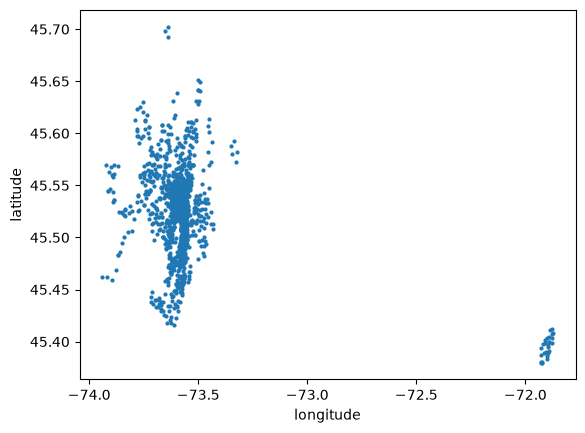

In [9]:
import matplotlib.pyplot as plt

# La station de test est en (0, 0) : on l'enlève, au départ comme à l'arrivée
station_test = "Test ECO5.1.1"
trajets = trajets[(trajets["STARTSTATIONNAME"] != station_test) & (trajets["ENDSTATIONNAME"] != station_test)]
print(f"{len(trajets):,} trajets ; distance maximale : {trajets['distance_km'].max():.1f} km")

# Chaque station de départ, une seule fois, à ses coordonnées
stations = trajets.groupby("STARTSTATIONNAME")[["STARTSTATIONLATITUDE", "STARTSTATIONLONGITUDE"]].first()
plt.scatter(stations["STARTSTATIONLONGITUDE"], stations["STARTSTATIONLATITUDE"], s=4)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.show()


In [10]:
stations[stations["STARTSTATIONLONGITUDE"] > -72.5].index.tolist()

['10e Avenue Nord / King Est',
 '7e Avenue Sud / King Est',
 'Cégep de Sherbrooke (du Cégep / Terrill)',
 'Denault / Claire-Jolicoeur',
 'Galt Ouest / Belvédère Sud',
 'Galt Ouest / McManamy',
 'Galt Ouest / Tétreault',
 'Gillespie / King Ouest',
 'LaRocque / de Mère-Teresa',
 'Marché de la Gare (Belvédère Sud / de la Gare)',
 'Marcil / King Ouest',
 'McManamy / Belvédère Sud',
 'Murray / Woodward',
 'Murray / du Conseil',
 'Parc Adrien-Cambron (7e Avenue Nord / Zéphirin-Cormier)',
 'Parc Jacques-Cartier (Marcil / Jacques-Cartier Sud)',
 'Parc Lucien-Blanchard (de la Pointe / Cabana)',
 'Queen-Victoria / de Portland',
 'U. de Sherbrooke (Pavillon Marie-Victorin - Voie 1)',
 'U. de Sherbrooke (Pavillon de la vie étudiante - Voie 3)',
 'U. de Sherbrooke (Registrariat - Voie 3)',
 'U. de Sherbrooke (École de musique - Voie 1)',
 'Veilleux / Dunant',
 'Wellington Nord / Meadow',
 'Wellington Sud / Sanborn',
 "de l'Ancienne-Carrière / de Kingston",
 "de l'Ontario / Walton"]

In [11]:
# Sherbrooke : un autre réseau BIXI, à environ 130 km. On garde seulement Montréal.
limite_est_montreal = -72.5   # longitude : plus à l'est que ça, on n'est plus à Montréal
avant = len(trajets)
trajets = trajets[(trajets["STARTSTATIONLONGITUDE"] < limite_est_montreal)
                  & (trajets["ENDSTATIONLONGITUDE"] < limite_est_montreal)]
print(f"Sherbrooke : {avant - len(trajets):,} trajets enlevés ; il en reste {len(trajets):,}")
print(f"Distance maximale : {trajets['distance_km'].max():.1f} km")

Sherbrooke : 16,738 trajets enlevés ; il en reste 13,605,052
Distance maximale : 29.1 km


## 5. Découpage dans le temps

Entraînement d'avril à août, validation en septembre, test scellé en octobre ; un échantillon de chaque morceau.

In [12]:
print(trajets["mois"].value_counts().sort_index())

# Découpage dans le temps, puis un échantillon de chaque bout (graine 0 : même tirage à chaque fois)
entrainement = trajets[trajets["mois"].between(4, 8)].sample(1_000_000, random_state=0)   # avril à août
validation = trajets[trajets["mois"] == 9].sample(200_000, random_state=0)                 # septembre
test = trajets[trajets["mois"] == 10].sample(200_000, random_state=0)                      # octobre, scellé

for nom, morceau in [("entraînement", entrainement), ("validation", validation), ("test", test)]:
    print(f"{nom} : {len(morceau):,} trajets, durée médiane {morceau['duree_min'].median():.2f} min")

mois
1       69492
2       41281
3      120574
4      682974
5     1520103
6     2121128
7     2219474
8     2185294
9     2140435
10    1700095
11     709340
12      94862
Name: count, dtype: int64
entraînement : 1,000,000 trajets, durée médiane 10.80 min
validation : 200,000 trajets, durée médiane 10.36 min
test : 200,000 trajets, durée médiane 9.62 min


## 6. Bases simples

La barre à battre : la médiane, puis la distance divisée par la vitesse médiane.

In [13]:
def erreur_absolue_moyenne(vraie, predite):
    """En moyenne, de combien de minutes la prédiction se trompe."""
    return np.mean(np.abs(np.asarray(vraie) - np.asarray(predite)))

# Règle 1 : chaque trajet dure la durée médiane de l'entraînement
mediane = entrainement["duree_min"].median()

# Règle 2 : durée = distance ÷ vitesse typique (vitesse médiane de l'entraînement, en km par minute)
vitesse = (entrainement["distance_km"] / entrainement["duree_min"]).median()

print(f"Vitesse médiane : {vitesse * 60:.1f} km/h")
print(f"Règle 1, médiane  : {erreur_absolue_moyenne(validation['duree_min'], mediane):.2f} min d'erreur")
print(f"Règle 2, distance : {erreur_absolue_moyenne(validation['duree_min'], validation['distance_km'] / vitesse):.2f} min d'erreur")

Vitesse médiane : 9.5 km/h
Règle 1, médiane  : 7.33 min d'erreur
Règle 2, distance : 3.90 min d'erreur


## 7. Boosting de gradient

Les stations entrent par leurs coordonnées (plus de 255 catégories) ; la cible est le logarithme de la durée.

In [14]:
import time
from sklearn.ensemble import HistGradientBoostingRegressor

# pas de « mois » : l'entraînement n'a jamais vu septembre ni octobre, la variable ne lui apprendrait rien d'utile
variables = ["distance_km", "STARTSTATIONLATITUDE", "STARTSTATIONLONGITUDE",
             "ENDSTATIONLATITUDE", "ENDSTATIONLONGITUDE", "heure", "jour"]

debut = time.time()
boosting = HistGradientBoostingRegressor(random_state=0)
boosting.fit(entrainement[variables], np.log(entrainement["duree_min"]))   # il apprend le log de la durée
print(f"Entraînement : {time.time() - debut:.0f} s")

prediction_min = np.exp(boosting.predict(validation[variables]))   # exp défait le log : retour en minutes
print(f"Boosting : {erreur_absolue_moyenne(validation['duree_min'], prediction_min):.2f} min d'erreur")

Entraînement : 4 s
Boosting : 3.59 min d'erreur


## 8. Des stations aux tenseurs

Un numéro par station vue à l'entraînement ; 0 pour une station inconnue.

In [15]:
import torch

# Un numéro par station vue à l'entraînement, à partir de 1 ; le 0 est réservé aux inconnues
stations_vues = sorted(set(entrainement["STARTSTATIONNAME"]) | set(entrainement["ENDSTATIONNAME"]))
numero_station = {nom: numero for numero, nom in enumerate(stations_vues, start=1)}
nombre_de_numeros = len(stations_vues) + 1   # + 1 pour le 0
print(f"Stations vues à l'entraînement : {len(stations_vues)}")

def en_tenseurs(morceau):
    """Les colonnes utiles d'un morceau, en tenseurs PyTorch."""
    return {
        "depart": torch.tensor(morceau["STARTSTATIONNAME"].map(numero_station).fillna(0).to_numpy(), dtype=torch.long),
        "arrivee": torch.tensor(morceau["ENDSTATIONNAME"].map(numero_station).fillna(0).to_numpy(), dtype=torch.long),
        "heure": torch.tensor(morceau["heure"].to_numpy(), dtype=torch.long),
        "jour": torch.tensor(morceau["jour"].to_numpy(), dtype=torch.long),
        "distance": torch.tensor(morceau["distance_km"].to_numpy(), dtype=torch.float32),
        "log_duree": torch.tensor(np.log(morceau["duree_min"].to_numpy()), dtype=torch.float32),
    }

tenseurs_entrainement = en_tenseurs(entrainement)
tenseurs_validation = en_tenseurs(validation)
tenseurs_test = en_tenseurs(test)

inconnues = (tenseurs_validation["depart"] == 0).sum().item()
print(f"Départs de stations inconnues en validation : {inconnues:,} sur {len(validation):,}")
print(tenseurs_entrainement["depart"][:5])
print(tenseurs_entrainement["distance"][:5])

Stations vues à l'entraînement : 1171
Départs de stations inconnues en validation : 2,253 sur 200,000
tensor([388, 172, 409, 693, 575])
tensor([2.3730, 3.5380, 0.3187, 1.4582, 2.1465])


## 9. Le réseau à plongements

Quatre tables de plongements (départ, arrivée, heure, jour) et la distance, puis des couches de 64, 32 et 1 neurones.

In [16]:
class ReseauDuree(torch.nn.Module):
    """Stations, heure et jour en plongements, plus la distance → log de la durée."""

    def __init__(self, nombre_de_numeros, dimension_station=8):
        super().__init__()
        self.table_depart = torch.nn.Embedding(nombre_de_numeros, dimension_station)    # ② 1 172 lignes × 8
        self.table_arrivee = torch.nn.Embedding(nombre_de_numeros, dimension_station)
        self.table_heure = torch.nn.Embedding(24, 4)
        self.table_jour = torch.nn.Embedding(7, 3)
        self.couches = torch.nn.Sequential(                                              # ④
            torch.nn.Linear(2 * dimension_station + 4 + 3 + 1, 64), torch.nn.ReLU(),     # 24 → 64
            torch.nn.Linear(64, 32), torch.nn.ReLU(),                                    # 64 → 32
            torch.nn.Linear(32, 1),                                                      # 32 → 1
        )

    def forward(self, depart, arrivee, heure, jour, distance):
        entree = torch.cat([                                                             # ③
            self.table_depart(depart), self.table_arrivee(arrivee),
            self.table_heure(heure), self.table_jour(jour),
            distance.unsqueeze(1),   # la distance est une liste plate : on en fait une colonne pour la coller
        ], dim=1)                    # dim=1 : on colle côte à côte, pas l'un sous l'autre
        return self.couches(entree).squeeze(1)                                           # ⑤ le log de la durée

torch.manual_seed(0)   # mêmes nombres du hasard à chaque fois
reseau = ReseauDuree(nombre_de_numeros)
print(reseau)
print(f"Paramètres : {sum(p.numel() for p in reseau.parameters()):,}")

# Essai sur 3 trajets, avant tout entraînement
t = tenseurs_entrainement
with torch.no_grad():
    essai = reseau(t["depart"][:3], t["arrivee"][:3], t["heure"][:3], t["jour"][:3], t["distance"][:3])
print("Prédit (min) :", torch.exp(essai))
print("Vrai   (min) :", torch.exp(t["log_duree"][:3]))

ReseauDuree(
  (table_depart): Embedding(1172, 8)
  (table_arrivee): Embedding(1172, 8)
  (table_heure): Embedding(24, 4)
  (table_jour): Embedding(7, 3)
  (couches): Sequential(
    (0): Linear(in_features=24, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Paramètres : 22,582
Prédit (min) : tensor([0.9981, 1.0142, 1.0374])
Vrai   (min) : tensor([15.6784, 24.7435,  2.6037])


## 10. Entraînement

Perte quadratique sur le logarithme de la durée, Adam au pas de 0,003, lots de 1 000 trajets, cinq époques.

In [17]:
torch.manual_seed(0)
reseau = ReseauDuree(nombre_de_numeros)        # on repart du hasard : relancer la cellule = tout recommencer
optimiseur = torch.optim.Adam(reseau.parameters(), lr=3e-3)
fonction_de_perte = torch.nn.MSELoss()         # MSE sur le log de la durée
taille_lot, nombre_epoques = 1000, 5
t, v = tenseurs_entrainement, tenseurs_validation
nombre_de_trajets = len(t["log_duree"])

for epoque in range(1, nombre_epoques + 1):
    debut = time.time()
    reseau.train()
    ordre = torch.randperm(nombre_de_trajets)  # un nouvel ordre à chaque époque : des lots différents
    for i in range(0, nombre_de_trajets, taille_lot):
        lot = ordre[i:i + taille_lot]
        prediction = reseau(t["depart"][lot], t["arrivee"][lot], t["heure"][lot], t["jour"][lot], t["distance"][lot])   # ①
        perte = fonction_de_perte(prediction, t["log_duree"][lot])                                                         # ②
        optimiseur.zero_grad()   # efface la direction du lot précédent
        perte.backward()                                                                                                   # ③
        optimiseur.step()                                                                                                  # ④

    reseau.eval()
    with torch.no_grad():        # pour juger, pas besoin de gradient : plus rapide
        prediction_min = torch.exp(reseau(v["depart"], v["arrivee"], v["heure"], v["jour"], v["distance"]))
    erreur = erreur_absolue_moyenne(torch.exp(v["log_duree"]).numpy(), prediction_min.numpy())
    print(f"Époque {epoque} : {time.time() - debut:.0f} s ; erreur de validation {erreur:.2f} min")

Époque 1 : 3 s ; erreur de validation 3.86 min
Époque 2 : 3 s ; erreur de validation 3.69 min
Époque 3 : 2 s ; erreur de validation 3.73 min
Époque 4 : 2 s ; erreur de validation 3.73 min
Époque 5 : 2 s ; erreur de validation 3.76 min


## 11. Optimiseur et pas d'apprentissage

Quatre réglages sur une époque, puis deux pas d'Adam sur cinq époques.

In [21]:
def entrainer(optimiseur_nom, taux, nombre_epoques, taille_lot=1000, classe_reseau=ReseauDuree):
    """Entraîne un réseau neuf ; renvoie le réseau et son erreur de validation (min) à chaque époque."""
    torch.manual_seed(0)
    reseau = classe_reseau(nombre_de_numeros)
    classe_optimiseur = {"sgd": torch.optim.SGD, "adam": torch.optim.Adam}[optimiseur_nom]
    optimiseur = classe_optimiseur(reseau.parameters(), lr=taux)
    fonction_de_perte = torch.nn.MSELoss()
    t, v = tenseurs_entrainement, tenseurs_validation
    nombre_de_trajets = len(t["log_duree"])
    erreurs = []
    for epoque in range(nombre_epoques):
        reseau.train()
        ordre = torch.randperm(nombre_de_trajets)
        for i in range(0, nombre_de_trajets, taille_lot):
            lot = ordre[i:i + taille_lot]
            prediction = reseau(t["depart"][lot], t["arrivee"][lot], t["heure"][lot], t["jour"][lot], t["distance"][lot])
            perte = fonction_de_perte(prediction, t["log_duree"][lot])
            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()
        reseau.eval()
        with torch.no_grad():
            prediction_min = torch.exp(reseau(v["depart"], v["arrivee"], v["heure"], v["jour"], v["distance"]))
        erreurs.append(erreur_absolue_moyenne(torch.exp(v["log_duree"]).numpy(), prediction_min.numpy()))
    return reseau, erreurs

# Une seule époque chacun, pour comparer le départ de la course
for optimiseur_nom, taux in [("sgd", 1e-2), ("adam", 1e-4), ("adam", 3e-3), ("adam", 1e-1)]:
    _, erreurs = entrainer(optimiseur_nom, taux, nombre_epoques=1)
    print(f"{optimiseur_nom} {taux:g} : {erreurs[0]:.2f} min")

sgd 0.01 : 6.03 min
adam 0.0001 : 11.26 min
adam 0.003 : 3.86 min
adam 0.1 : 3.76 min


In [19]:
for taux in [3e-3, 1e-1]:
    _, erreurs = entrainer("adam", taux, nombre_epoques=5)
    print(f"adam {taux:g} :", " ; ".join(f"{e:.2f}" for e in erreurs))

adam 0.003 : 3.86 ; 3.69 ; 3.73 ; 3.73 ; 3.76
adam 0.1 : 3.76 ; 3.73 ; 3.78 ; 3.77 ; 4.04


## 12. Les plongements retrouvent-ils la carte ?

Réseau arrêté à la 2e époque. Corrélation de Spearman entre distances réelles et distances entre plongements, sur des paires de stations d'au moins 300 départs.

In [20]:
from scipy.stats import spearmanr

reseau, erreurs = entrainer("adam", 3e-3, nombre_epoques=2)   # arrêt précoce : le réseau à 3,69

departs = entrainement["STARTSTATIONNAME"].value_counts()
frequentes = departs[departs >= 300].index
coord = entrainement.groupby("STARTSTATIONNAME")[["STARTSTATIONLATITUDE", "STARTSTATIONLONGITUDE"]].first().loc[frequentes]
plongements = reseau.table_depart.weight.detach().numpy()[[numero_station[s] for s in frequentes]]   # leurs lignes de 8 nombres

generateur = np.random.default_rng(0)
i = generateur.integers(0, len(frequentes), 20_000)
j = generateur.integers(0, len(frequentes), 20_000)
i, j = i[i != j], j[i != j]                                    # pas de paire d'une station avec elle-même
lat, lon = coord["STARTSTATIONLATITUDE"].to_numpy(), coord["STARTSTATIONLONGITUDE"].to_numpy()
distance_carte = distance_km(lat[i], lon[i], lat[j], lon[j])
distance_plongement = np.linalg.norm(plongements[i] - plongements[j], axis=1)

print(f"Stations avec au moins 300 départs : {len(frequentes)}")
print(f"Spearman, carte contre plongements : {spearmanr(distance_carte, distance_plongement).statistic:.2f}")

Stations avec au moins 300 départs : 726
Spearman, carte contre plongements : 0.04


## 13. Réseau carte : sans la distance

Une seule table de positions (x, y) pour le départ et l'arrivée ; le réseau ne voit que l'écart entre les deux positions.

In [22]:
class ReseauCarte(torch.nn.Module):
    """Une seule table de 2 nombres par station : sa position (x, y) sur une carte inventée.
    Pas de distance en entrée : le réseau ne voit que l'écart entre les deux positions, l'heure et le jour."""

    def __init__(self, nombre_de_numeros):
        super().__init__()
        self.table_position = torch.nn.Embedding(nombre_de_numeros, 2)   # la même table pour le départ et l'arrivée
        self.table_heure = torch.nn.Embedding(24, 4)
        self.table_jour = torch.nn.Embedding(7, 3)
        self.couches = torch.nn.Sequential(torch.nn.Linear(1 + 4 + 3, 32), torch.nn.ReLU(), torch.nn.Linear(32, 1))

    def forward(self, depart, arrivee, heure, jour, distance):   # la distance arrive mais n'est jamais utilisée
        ecart = (self.table_position(depart) - self.table_position(arrivee)).norm(dim=1, keepdim=True)   # Pythagore sur sa carte
        entree = torch.cat([torch.log1p(ecart), self.table_heure(heure), self.table_jour(jour)], dim=1)   # log, comme la cible
        return self.couches(entree).squeeze(1)

# Sa carte part d'un nuage au hasard : un pas plus grand et plus d'époques pour déplacer 1 171 stations
reseau_carte, erreurs_carte = entrainer("adam", 1e-2, nombre_epoques=12, classe_reseau=ReseauCarte)

def correlation_avec_la_carte(table):
    """Spearman sur les mêmes 20 000 paires que plus haut : la comparaison est équitable."""
    plongements = table.weight.detach().numpy()[[numero_station[s] for s in frequentes]]
    return spearmanr(distance_carte, np.linalg.norm(plongements[i] - plongements[j], axis=1)).statistic

print("Erreur de validation par époque :", " ; ".join(f"{e:.2f}" for e in erreurs_carte))
print(f"Spearman, réseau à distance donnée : {correlation_avec_la_carte(reseau.table_depart):.2f}")
print(f"Spearman, réseau carte             : {correlation_avec_la_carte(reseau_carte.table_position):.2f}")


Erreur de validation par époque : 6.17 ; 5.99 ; 5.87 ; 5.58 ; 5.26 ; 5.17 ; 5.20 ; 5.01 ; 5.19 ; 5.06 ; 5.07 ; 4.93
Spearman, réseau à distance donnée : 0.04
Spearman, réseau carte             : 0.41


## 14. La carte apprise

Alignement par rotation orthogonale (Procrustes) sur les stations les plus centrales.

Distance au centre, vraie contre apprise (Spearman) : 0.76


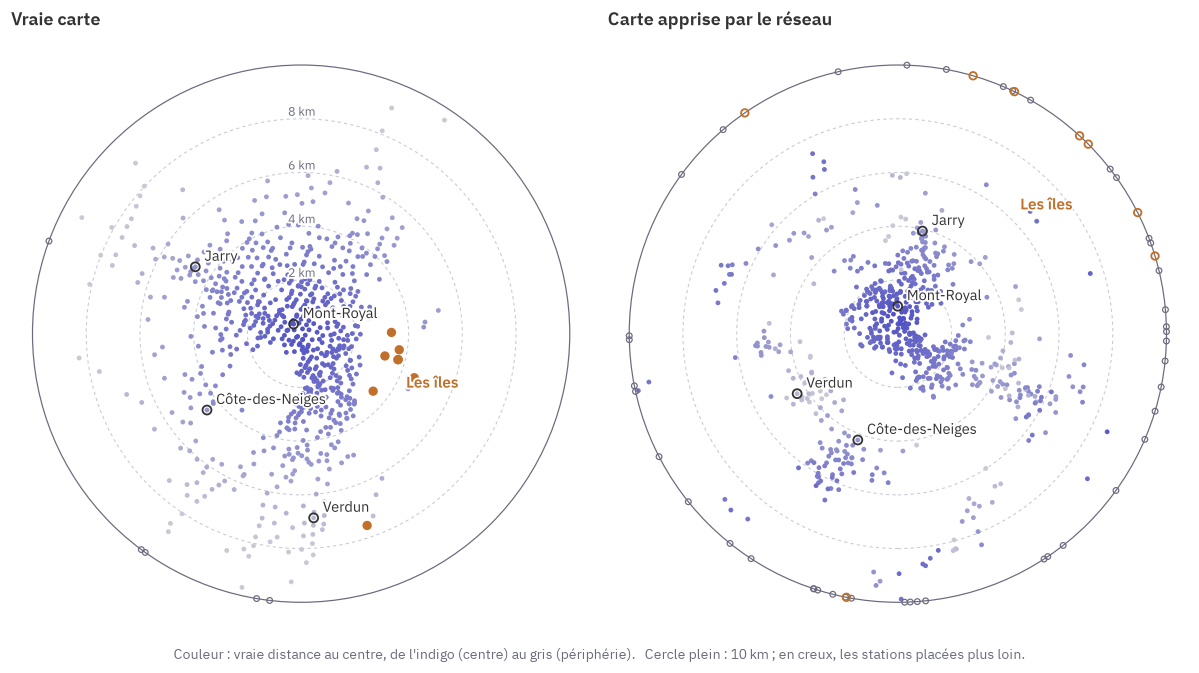

In [24]:
import sys
import matplotlib.patheffects as effets
from scipy.linalg import orthogonal_procrustes
from scipy.stats import spearmanr
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, "../../style")
from charte import charger_charte, sauver_clair_et_sombre
charger_charte()

# Les deux cartes, centrées sur leur station médiane
vraie = np.column_stack([lon * 79, lat * 111])     # en km : 79 km par degré de longitude, 111 par degré de latitude
vraie = vraie - np.median(vraie, axis=0)
apprise_brute = reseau_carte.table_position.weight.detach().numpy()[[numero_station[s] for s in frequentes]]
apprise = apprise_brute - np.median(apprise_brute, axis=0)
rayon_vrai = np.linalg.norm(vraie, axis=1)
apprise = apprise * np.median(rayon_vrai) / np.median(np.linalg.norm(apprise, axis=1))   # même rayon médian : même échelle
# Pour le réseau, l'orientation n'a pas de sens : on tourne (ou retourne) sa carte pour la superposer au mieux,
# en se fiant au cœur du réseau (les 90 % de stations les plus centrales)
coeur = rayon_vrai < np.quantile(rayon_vrai, 0.9)
rotation, _ = orthogonal_procrustes(apprise[coeur], vraie[coeur])
apprise = apprise @ rotation
print(f"Distance au centre, vraie contre apprise (Spearman) : {spearmanr(rayon_vrai, np.linalg.norm(apprise, axis=1)).statistic:.2f}")

mots_des_iles = ("Jean-Drapeau", "Casino", "La Ronde", "navette fluviale", "Dieppe", "Île-des-Sœurs")
est_une_ile = np.array([any(mot in nom for mot in mots_des_iles) for nom in frequentes])
reperes = {
    "Métro Mont-Royal (Utilités publiques / Rivard)": "Mont-Royal",
    "Métro Jarry (Lajeunesse / Jarry)": "Jarry",
    "Métro Côte-des-Neiges (Jean-Brillant / de la Côte-des-Neiges)": "Côte-des-Neiges",
    "Métro Verdun (Willibrord / de Verdun)": "Verdun",
}
position = {nom: k for k, nom in enumerate(frequentes)}
RAYON_CADRE = 10   # km : au-delà, une station est posée sur le bord du cadre, en creux

def dans_le_cadre(points):
    """Ramène sur le bord du cadre les stations placées plus loin ; renvoie aussi lesquelles."""
    rayon = np.linalg.norm(points, axis=1, keepdims=True)
    return np.where(rayon > RAYON_CADRE, points * RAYON_CADRE / rayon, points), rayon[:, 0] > RAYON_CADRE

def tracer_cartes(couleurs):
    degrade = LinearSegmentedColormap.from_list("centre_periph", [couleurs["accent"], couleurs["neutre"]])
    halo = [effets.withStroke(linewidth=2.5, foreground=plt.rcParams["axes.facecolor"])]
    figure, axes = plt.subplots(1, 2, figsize=(11, 5.8))
    for ax, points_bruts, titre in [(axes[0], vraie, "Vraie carte"), (axes[1], apprise, "Carte apprise par le réseau")]:
        points, hors_cadre = dans_le_cadre(points_bruts)
        for rayon in (2, 4, 6, 8):
            ax.add_patch(plt.Circle((0, 0), rayon, fill=False, color=couleurs["neutre"], linewidth=0.7, linestyle=(0, (3, 3))))
        ax.add_patch(plt.Circle((0, 0), RAYON_CADRE, fill=False, color=couleurs["trait"], linewidth=0.8))
        normales = ~est_une_ile & ~hors_cadre
        ax.scatter(points[normales, 0], points[normales, 1], c=rayon_vrai[normales], cmap=degrade, vmin=0, vmax=8, s=10, linewidths=0)
        ax.scatter(points[~est_une_ile & hors_cadre, 0], points[~est_une_ile & hors_cadre, 1], s=14,
                   facecolors="none", edgecolors=couleurs["trait"], linewidths=0.8)
        ax.scatter(points[est_une_ile, 0], points[est_une_ile, 1], s=24, linewidths=1.2, zorder=3,
                   facecolors=np.where(hors_cadre[est_une_ile], "none", couleurs["second"]).tolist(), edgecolors=couleurs["second"])
        x, y = points[est_une_ile].mean(axis=0)
        ax.annotate("Les îles", (x, y), xytext=(10, -4), textcoords="offset points", color=couleurs["second"],
                    fontsize=10, fontweight="semibold", path_effects=halo)
        for nom, etiquette in reperes.items():
            x, y = points[position[nom]]
            ax.scatter(x, y, s=34, facecolors="none", edgecolors=couleurs["texte"], linewidths=1.2, zorder=4)
            ax.annotate(etiquette, (x, y), xytext=(6, 4), textcoords="offset points", color=couleurs["texte"],
                        fontsize=9.5, path_effects=halo)
        ax.set_title(titre)
        ax.set_xlim(-RAYON_CADRE * 1.08, RAYON_CADRE * 1.08)
        ax.set_ylim(-RAYON_CADRE * 1.08, RAYON_CADRE * 1.08)
        ax.set_aspect("equal")
        ax.set_axis_off()
    for rayon in (2, 4, 6, 8):
        axes[0].annotate(f"{rayon} km", (0, rayon), xytext=(0, 2), textcoords="offset points", ha="center",
                         color=couleurs["secondaire"], fontsize=8, path_effects=halo)
    figure.tight_layout()
    figure.text(0.5, -0.01, "Couleur : vraie distance au centre, de l'indigo (centre) au gris (périphérie).   "
                "Cercle plein : 10 km ; en creux, les stations placées plus loin.", ha="center", color=couleurs["secondaire"], fontsize=9)
    return figure

sauver_clair_et_sombre(tracer_cartes, "resultats/carte_apprise")

## 15. Mesure en local

Processeur seulement : temps d'entraînement et de prédiction, taille des modèles enregistrés.

In [25]:
import os
import pickle

def mesurer(fonction, repetitions=5):
    """Temps médian d'un appel, en secondes : la médiane écarte un appel ralenti par Windows."""
    temps = []
    for _ in range(repetitions):
        debut = time.perf_counter()
        fonction()
        temps.append(time.perf_counter() - debut)
    return float(np.median(temps))

v = tenseurs_validation
un_trajet = {nom: tenseur[:1] for nom, tenseur in v.items()}
X_validation = validation[variables]

def predire_reseau(t):
    with torch.no_grad():
        return reseau(t["depart"], t["arrivee"], t["heure"], t["jour"], t["distance"])

mesures = {
    "Boosting": {
        "entraînement (s)": mesurer(lambda: HistGradientBoostingRegressor(random_state=0).fit(
            entrainement[variables], np.log(entrainement["duree_min"])), repetitions=1),
        "200 000 trajets (s)": mesurer(lambda: boosting.predict(X_validation)),
        "1 trajet (ms)": 1000 * mesurer(lambda: boosting.predict(X_validation.iloc[:1]), repetitions=50),
    },
    "Réseau": {
        "entraînement (s)": mesurer(lambda: entrainer("adam", 3e-3, nombre_epoques=2), repetitions=1),
        "200 000 trajets (s)": mesurer(lambda: predire_reseau(v)),
        "1 trajet (ms)": 1000 * mesurer(lambda: predire_reseau(un_trajet), repetitions=50),
    },
}

torch.save(reseau.state_dict(), "donnees/reseau.pt")
with open("donnees/boosting.pkl", "wb") as fichier:
    pickle.dump(boosting, fichier)
mesures["Boosting"]["taille (Ko)"] = os.path.getsize("donnees/boosting.pkl") / 1024
mesures["Réseau"]["taille (Ko)"] = os.path.getsize("donnees/reseau.pt") / 1024

print(f"Processeur seulement, {torch.get_num_threads()} fils pour PyTorch")
pd.DataFrame(mesures).round(3)

Processeur seulement, 4 fils pour PyTorch


,Boosting,Réseau
entraînement (s),3.861,5.367
200 000 trajets (s),0.347,0.033
1 trajet (ms),1.444,0.120
taille (Ko),358.468,91.864


## 16. Test scellé

Les cinq modèles, figés sur la validation, jugés une seule fois sur octobre.

In [26]:
def predictions_en_minutes(morceau, tenseurs):
    """Les 5 modèles figés, appliqués à un morceau (validation ou test)."""
    entrees = (tenseurs["depart"], tenseurs["arrivee"], tenseurs["heure"], tenseurs["jour"], tenseurs["distance"])
    with torch.no_grad():
        return {
            "Médiane": np.full(len(morceau), mediane),
            "Distance ÷ vitesse": morceau["distance_km"].to_numpy() / vitesse,
            "Boosting": np.exp(boosting.predict(morceau[variables])),
            "Réseau, distance donnée": torch.exp(reseau(*entrees)).numpy(),   # * : passe les 5 tenseurs comme 5 arguments
            "Réseau carte": torch.exp(reseau_carte(*entrees)).numpy(),
        }

tableau_erreurs = pd.DataFrame({
    nom: {modele: erreur_absolue_moyenne(morceau["duree_min"], prediction)
          for modele, prediction in predictions_en_minutes(morceau, tenseurs).items()}
    for nom, morceau, tenseurs in [("validation (septembre)", validation, tenseurs_validation),
                                   ("test (octobre)", test, tenseurs_test)]
}).round(2)

tableau_erreurs.to_csv("resultats/erreurs_validation_test.csv")   # petit CSV de résultats : il ira dans le dépôt
tableau_erreurs

,validation (septembre),test (octobre)
Médiane,7.33,6.82
Distance ÷ vitesse,3.90,3.53
Boosting,3.59,3.28
"Réseau, distance donnée",3.69,3.34
Réseau carte,4.93,4.82
